# Spectral Clustering

![](img/banner.png)

**Computer Science Dept, Ferdowsi University of Mashhad**


## Where this page sits

Section 14.5.3 of {cite}`hastie2009esl` (pp. 544-547) is about the situation in which K-means is not
merely slow but *wrong*. The book opens the section with the sentence that motivates everything
that follows (p. 544):

> Traditional clustering methods like K-means use a spherical or elliptical metric to group data
> points. Hence they will not work well when the clusters are non-convex, such as the concentric
> circles in the top left panel of Figure 14.29.

The remedy the book proposes is a change of representation: instead of clustering points in their
own space, build a *graph* on the points, and cluster the graph. The whole method then rests on one
sentence (p. 547):

> We now use the eigenvectors corresponding to the $m$ smallest eigenvalues of $L$ to define a new
> feature space, and then run K-means on this new space.

That sentence is short, and the book does not prove it. This page fills in the missing middle: why
the eigenvectors of the graph Laplacian are the right coordinates, where they come from (graph
cuts), and what the two free parameters of the graph do to the answer.

The two theses behind this page {cite}`Fayaz2015Spectral, Nemati2018Gradient` work on exactly the
two questions the book's section leaves open in practice: which graph and which parameters
(threshold, kernel scale, number of neighbours, number of clusters) to use, and what to do when
the graph has a million vertices, so that $L$ cannot even be stored.

### What you should be able to do at the end

* Explain, with the identity (14.64), *why* the second eigenvector of the Laplacian separates two
  clusters, and why the multiplicity of the zero eigenvalue counts the connected components.
* Write down mincut, ratio cut and normalized cut for a graph, and say what is wrong with the first.
* Derive the relaxation that turns a cut problem into an eigenproblem, and implement the resulting
  algorithm in a dozen lines on top of `scipy.sparse`.
* Predict what happens to the answer when the neighbour count $k$ in the graph is too small, and
  when $k$ is so large that the graph is almost complete.
* Explain the Nystrom approximation, and why sampling rows by their norm is more stable than
  sampling them uniformly.


## 1. The failure is in the metric, not in the clustering

Look at the data first. The book's toy example (Figure 14.29, p. 545) is three concentric rings of
150 points each, radii $1, 2.8, 5$, with Gaussian noise of standard deviation $0.25$ added to every
coordinate. In this picture the clusters are obvious to the eye and hopeless for K-means: K-means
partitions the plane by perpendicular bisectors of centroids, i.e. into convex cells, and no union
of convex cells is a ring.

The next cell builds the data and runs K-means on the raw coordinates.


n = 450   K-means on the raw coordinates: ARI = -0.001


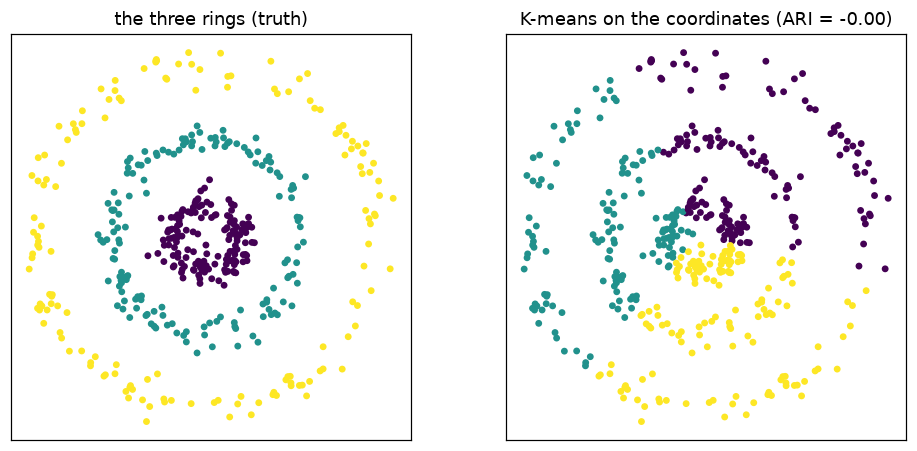

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, diags
from scipy.sparse.csgraph import connected_components
from scipy.sparse.linalg import eigsh
from sklearn.cluster import KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import kneighbors_graph

plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(0)


def rings(n_per_ring=150, radii=(1.0, 2.8, 5.0), noise=0.25, seed=0):
    "Three concentric rings with Gaussian noise, after Figure 14.29."
    g = np.random.default_rng(seed)
    pts, truth = [], []
    for j, r in enumerate(radii):
        theta = g.uniform(0.0, 2 * np.pi, n_per_ring)
        ring = np.column_stack([r * np.cos(theta), r * np.sin(theta)])
        pts.append(ring + g.normal(0.0, noise, size=ring.shape))
        truth.append(np.full(n_per_ring, j))
    return np.vstack(pts), np.concatenate(truth)


X, truth = rings()
km = KMeans(n_clusters=3, n_init=20, random_state=0).fit(X)
ari_km = adjusted_rand_score(truth, km.labels_)
print(f"n = {len(X)}   K-means on the raw coordinates: ARI = {ari_km:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(9.2, 4.2))
ax[0].scatter(X[:, 0], X[:, 1], c=truth, s=12, cmap="viridis")
ax[0].set_title("the three rings (truth)")
ax[1].scatter(X[:, 0], X[:, 1], c=km.labels_, s=12, cmap="viridis")
ax[1].set_title(f"K-means on the coordinates (ARI = {ari_km:.2f})")
for a in ax:
    a.set_aspect("equal")
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()


The adjusted Rand index (defined on [Clustering Validation Metrics](Clustering-Validation-Metrics.ipynb))
compares two partitions and is $1$ for identical partitions, $0$ for agreement no better than chance. K-means on these coordinates stays close to
chance: its three cells cut every ring into pieces, because no straight line bisects a ring the way
the data require. Note also the shape of the failure: the loss K-means minimises (within-cluster
squared distance) does not see the rings at all, so *more iterations, better initialisation or a
different $K$ cannot repair it*. What is missing is not effort but a notion of "close" that follows
the ring.

That notion is easy to write down: two points are close if a short step takes you from one to the
other along the data. In other words, closeness should be **local and transitive**, and locality plus
transitivity is exactly what a graph encodes.


## 2. From points to a graph

Let the $N$ observations be vertices $1,\dots,N$ of a graph, and let $w_{ii'}\ge 0$ be the weight of
the edge between $i$ and $i'$. The book starts from a similarity
$s_{ii'} = \exp(-\|x_i-x_{i'}\|^2/c)$ with a scale parameter $c>0$, and keeps only some of the pairs:

| graph | edge set | parameter | what "close" means |
|---|---|---|---|
| fully connected | all pairs, $w_{ii'}=s_{ii'}$ | $c$ | distance in the ambient space, weighted |
| $k$-nearest-neighbour | $i\sim i'$ if $i$ is among the $k$ nearest neighbours of $i'$ **or** $i'$ is among the $k$ nearest of $i$ | $k$, $c$ | rank of the distance, locally |
| $\epsilon$-neighbourhood | $i\sim i'$ if $\|x_i-x_{i'}\|\le\epsilon$ | $\epsilon$ | a distance ball, radius fixed globally |

The $k$-nearest-neighbour graph is made *symmetric* by the "or" in the table, which is what the book
calls the set $N_K$. Its virtue is that it adapts: in a dense region the $k$ nearest neighbours are
very close, in a sparse region they are farther away, so the graph follows the local density instead
of a single global radius. Its price is that a point can win an edge it "did not ask for", so hubs
appear.

Two matrices summarise the graph. The adjacency matrix $W=(w_{ii'})$, and the degree matrix
$G=\operatorname{diag}(g_1,\dots,g_N)$ with $g_i=\sum_{i'}w_{ii'}$. The book then defines the (unnormalized)
graph Laplacian, equation (14.63):

$$L = G - W .$$

Because $g_i$ is the sum of row $i$, the row sums of $L$ are zero, so $L\mathbf 1=0$: the constant
vector is an eigenvector with eigenvalue $0$, and $L$ is symmetric positive semi-definite. Two
normalized versions are used in practice, and the difference between them matters later:

$$L_{\text{rw}} = I - G^{-1}W \qquad\text{(the book's }\tilde L\text{, equation 14.63)}
\qquad\qquad
L_{\text{sym}} = I - G^{-1/2}WG^{-1/2}.$$

$L_{\text{rw}}$ is not symmetric, so an eigensolver for symmetric matrices cannot be pointed at it
directly. It is nevertheless the same problem: $L_{\text{sym}} = G^{1/2}L_{\text{rw}}G^{-1/2}$, a
similarity transform, so the two have identical eigenvalues, and an eigenvector $u$ of
$L_{\text{sym}}$ corresponds to $G^{-1/2}u$ for $L_{\text{rw}}$. Everything below is computed with
$L_{\text{sym}}$, and the factor $G^{-1/2}$ is put back where it belongs.

The next cell builds the graph of the rings with $k=10$ and reports what kind of object came out.


In [2]:
def rbf_graph(X, c):
    "Fully connected graph with weights exp(-d^2 / c) and no self-loops."
    X = np.asarray(X, float)
    D2 = ((X[:, None, :] - X[None, :, :]) ** 2).sum(-1)
    W = np.exp(-D2 / c)
    np.fill_diagonal(W, 0.0)          # a self-loop would add 1 to every degree
    return csr_matrix(W)


def knn_graph(X, k, c, weighted=True):
    "Symmetric k-nearest-neighbour graph with weights exp(-d^2/c) or 1."
    A = kneighbors_graph(X, n_neighbors=k, mode="distance", include_self=False)
    A = A.maximum(A.T).tocoo()                     # the symmetric set N_K
    vals = np.exp(-(A.data ** 2) / c) if weighted else np.ones_like(A.data)
    W = csr_matrix((vals, (A.row, A.col)), shape=A.shape)
    W.eliminate_zeros()                            # an underflowed weight is not an edge
    return W


def laplacian(W, normalized=True):
    "Unnormalized L = G - W, or the symmetric normalized I - G^-1/2 W G^-1/2."
    d = np.asarray(W.sum(axis=1)).ravel()
    if not normalized:
        return (diags(d) - W).tocsr(), d
    s = 1.0 / np.sqrt(d)
    return (diags(np.ones_like(d)) - diags(s) @ W @ diags(s)).tocsr(), d


def eigen_embedding(W, m, normalized=True, dense_below=1500):
    "The m smallest eigenvalues and eigenvectors of the Laplacian of W."
    L, d = laplacian(W, normalized=normalized)
    if L.shape[0] <= dense_below:
        vals, vecs = np.linalg.eigh(L.toarray())
    else:                                          # sparse: Lanczos, no N x N array
        vals, vecs = eigsh(L.tocsc(), k=m + 1, sigma=-1e-5, which="LM")
        order = np.argsort(vals)
        vals, vecs = vals[order], vecs[:, order]
    return vals, vecs, d


def spectral(W, n_clusters, normalized=True, m=None, row_normalize=True, seed=0):
    "Spectral clustering: m eigenvectors, one row per vertex, then K-means."
    m = n_clusters if m is None else m
    vals, vecs, d = eigen_embedding(W, m, normalized=normalized)
    Z = vecs[:, 1 : m + 1]                          # drop the trivial eigenvector
    if row_normalize:
        Z = Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)
    return KMeans(n_clusters=n_clusters, n_init=20, random_state=seed).fit_predict(Z), Z, vals


k_nn = 10
nn = kneighbors_graph(X, n_neighbors=k_nn, mode="distance", include_self=False)
c0 = np.median(nn.data ** 2)                        # scale of the 10th neighbour
W = knn_graph(X, k_nn, c0)
d = np.asarray(W.sum(axis=1)).ravel()
n_comp = connected_components(W, directed=False)[0]

print(f"scale c0 = {c0:.3f}  (median squared distance to the 10th neighbour)")
print(f"edges: {W.nnz} of {len(X) ** 2} = {100 * W.nnz / len(X) ** 2:.1f} percent")
print(f"degree: min {d.min():.2f}, median {np.median(d):.2f}, max {d.max():.2f}")
print(f"edge weights: min {W.data.min():.3f}, max {W.data.max():.3f}")
print(f"connected components: {n_comp}")


scale c0 = 0.147  (median squared distance to the 10th neighbour)
edges: 5294 of 202500 = 2.6 percent
degree: min 0.02, median 3.78, max 13.30
edge weights: min 0.000, max 0.998
connected components: 1


The graph has a few thousand edges out of $450^2=202\,500$ possible pairs, so it is very sparse:
this is the property that makes the method scale, and it is what the sparse eigensolvers exploit.
It is also connected, which we will need: the ring points form a cycle, and a $10$-nearest-neighbour
graph follows that cycle.

## 3. What the Laplacian measures

Why should a matrix built from a graph know anything about clusters? Because for every vector
$f\in\mathbb{R}^N$ it computes a weighted measure of how much $f$ *varies across edges*. Expanding
$G-W$ gives the identity that the book prints as (14.64) (p. 546):

$$f^\top L f \;=\; \tfrac12 \sum_{i,i'} w_{ii'}\,(f_i - f_{i'})^2
\;=\; \sum_{i} g_i f_i^2 - \sum_{i,i'} w_{ii'} f_i f_{i'} .$$

*Proof.* Expand the square: $\tfrac12\sum_{i,i'}w(f_i^2 - 2f_if_{i'} + f_{i'}^2)$; the first term
gives $\tfrac12\sum_i f_i^2\sum_{i'}w_{ii'}=\tfrac12\sum_i g_if_i^2$, the third is the same by
symmetry of $W$, and they add to $\sum_i g_if_i^2$, leaving $-\sum_{i,i'}w_{ii'}f_if_{i'}$. That is
$f^\top(G-W)f$. $\square$

The book draws the consequence immediately:

> Formula 14.64 suggests that a small value of $f^\top Lf$ will be achieved if pairs of points with
> large adjacencies have coordinates $f_i$ and $f_{i'}$ close together.

Read it the other way round and it becomes a *statement about the eigenvectors*: the eigenvector of
the smallest eigenvalue is the vector that varies least across the edges of the graph. Since $L$ is
positive semi-definite, that minimum is $0$, and $f^\top Lf=0$ happens precisely when $f_i=f_{i'}$
on every edge with $w_{ii'}>0$ - that is, when $f$ is constant on each connected component.

Two consequences, which are the whole justification of the method:

1. If the graph has $m$ connected components, $0$ is an eigenvalue of multiplicity $m$, and the
   eigenspace is spanned by the indicator vectors of the components.
2. For a real graph, which is connected, $0$ is simple and its eigenvector is the constant vector -
   useless. The interesting one is the **second** eigenvector, the least-varying vector orthogonal
   to the constant one: the best split of the graph into two parts that are cheap to separate.

Point 1 is testable, and worth testing, because it explains both the success of the method and its
most annoying practical feature (the rotation ambiguity of the embedding).


three far-apart blobs: 3 connected components
four smallest eigenvalues of L: [0.         0.         0.         2.69948967]


K-means on the three null eigenvectors: ARI = 1.000


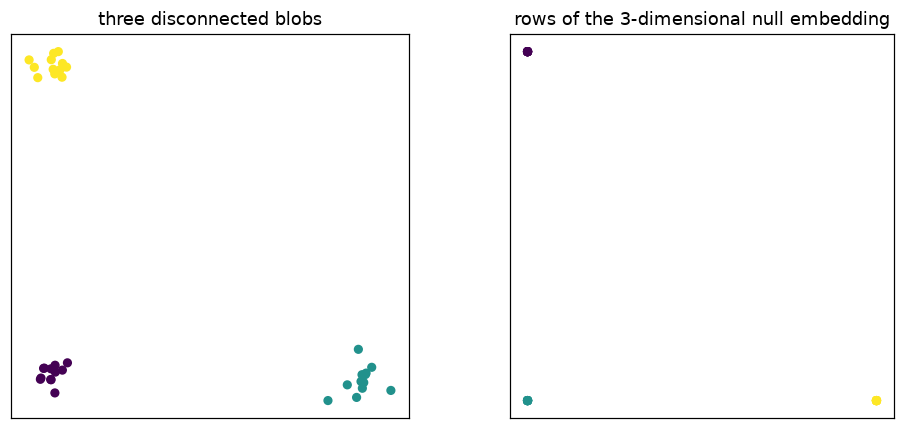

In [3]:
def blobs(centers, n=4, sd=0.25, seed=1):
    g = np.random.default_rng(seed)
    pts, lab = [], []
    for j, cen in enumerate(centers):
        pts.append(g.normal(cen, sd, size=(n, 2)))
        lab.append(np.full(n, j))
    return np.vstack(pts), np.concatenate(lab)


Xb, truth_b = blobs(((0.0, 0.0), (6.0, 0.0), (0.0, 6.0)), n=12)
cb = np.median(kneighbors_graph(Xb, 5, mode="distance", include_self=False).data ** 2)
Wb = knn_graph(Xb, 5, cb, weighted=False)          # unit weights: components are literal
vals_b, vecs_b, _ = eigen_embedding(Wb, 3, normalized=False)
n_b = connected_components(Wb, directed=False)[0]

print(f"three far-apart blobs: {n_b} connected components")
print("four smallest eigenvalues of L:", np.round(vals_b[:4], 12))

labels_b = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(vecs_b[:, :3])
print(f"K-means on the three null eigenvectors: ARI = {adjusted_rand_score(truth_b, labels_b):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(9.2, 4.0))
ax[0].scatter(Xb[:, 0], Xb[:, 1], c=truth_b, s=25, cmap="viridis")
ax[0].set_title("three disconnected blobs")
ax[1].scatter(vecs_b[:, 0], vecs_b[:, 1], c=truth_b, s=25, cmap="viridis")
ax[1].set_title("rows of the 3-dimensional null embedding")
for a in ax:
    a.set_aspect("equal")
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()


The eigenvalue $0$ has multiplicity exactly three, as many as the components, and the three
eigenvectors together span the space of functions that are constant on each blob. That space is
three-dimensional, so the particular triple `eigh` returns is an arbitrary orthogonal basis of it:
rotate the right panel and it is the same embedding. The clusters are the three *clusters of rows*,
not the signs of a single coordinate - which is the practical reason the method ends with K-means on
the rows of $Z$ instead of a threshold on one eigenvector.

So the ideal case is: $m$ components, $m$ zero eigenvalues, and the embedding is a rotated simplex.
On real data the graph is connected, $0$ is simple, and the remaining small eigenvalues are small
but positive. How small, and whether there is a visible gap, is an empirical question - and the
answer in the book's example is disappointing (Section 7 below).

## 4. Cuts, and why mincut is not enough

The informal goal "split the graph into two parts that are cheap to cut" has a name. For a subset
$A\subset V$ and its complement $B=V\setminus A$,

$$\operatorname{cut}(A,B)=\sum_{i\in A}\sum_{j\in B} w_{ij},
\qquad
\operatorname{vol}(A)=\sum_{i\in A} g_i .$$

The naive objective is $\min_A \operatorname{cut}(A,B)$, *mincut*. It has a trivial failure mode that
is easy to see on a small graph: shaving off one vertex that has a single weak edge costs almost
nothing, so the minimiser of the cut is often "one vertex against the world". The cost of an edge
is not the right currency, because cutting a small group is cheap by construction.

Two repairs are standard. The first divides the cut by the *sizes* of the two sides, the second by
their *volumes*:

$$\text{ratio cut: } \operatorname{RatioCut}(A,B)=\frac{\operatorname{cut}(A,B)}{|A|}+\frac{\operatorname{cut}(A,B)}{|B|},
\qquad
\text{normalized cut: } \operatorname{Ncut}(A,B)=\frac{\operatorname{cut}(A,B)}{\operatorname{vol}(A)}+\frac{\operatorname{cut}(A,B)}{\operatorname{vol}(B)} .$$

The normalized cut (Shi and Malik) is the objective used in {cite}`Fayaz2015Spectral`: dividing by
the volume turns the cut into a *fraction of the total edge weight leaving each side*, so a side is
only expensive to isolate if it carries a lot of weight. Both range over $[0,2]$ and are small only
when both sides are large and the cut is thin - which is exactly "two big groups separated by few
edges". The next cell computes the optimal mincut and the optimal Ncut by exhaustive search on a
$10$-vertex graph, so that the difference cannot be dismissed as hypothetical.


511 nontrivial partitions of 10 vertices examined
  best mincut: |A| =  9, |B| =  1, cut = 0.0053, objective = 0.0053  (outlier isolated)
  best Ncut  : |A| =  6, |B| =  4, cut = 5.7015, objective = 0.7291  (balanced)


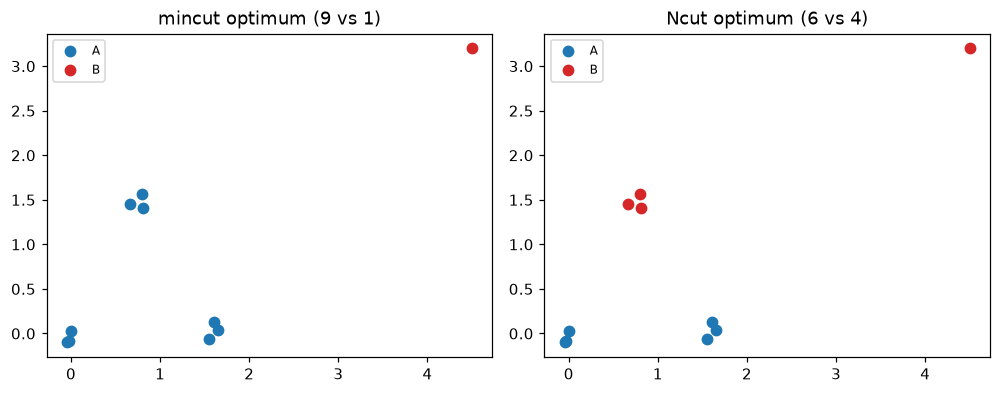

In [4]:
Xc, _ = blobs(((0.0, 0.0), (1.6, 0.0), (0.8, 1.5)), n=3, sd=0.10, seed=7)
Xs = np.vstack([Xc, [[4.5, 3.2]]])                 # three tight triples plus one outlier
cs = np.median(kneighbors_graph(Xs, 5, mode="distance", include_self=False).data ** 2)
Ws = rbf_graph(Xs, cs).toarray()
ds = Ws.sum(axis=1)
n = len(Xs)

best_cut = best_ncut = None
for code in range(2 ** (n - 1) - 1):               # vertex 0 in A, and B non-empty
    mask = np.array([True] + [bool((code >> i) & 1) for i in range(n - 1)])
    cut = Ws[np.ix_(mask, ~mask)].sum()
    val = cut / ds[mask].sum() + cut / ds[~mask].sum()
    if best_cut is None or cut < best_cut[0]:
        best_cut = (cut, mask)
    if best_ncut is None or val < best_ncut[0]:
        best_ncut = (val, mask)

print(f"{2 ** (n - 1) - 1} nontrivial partitions of {n} vertices examined")
for name, (obj, mask) in (("mincut", best_cut), ("Ncut", best_ncut)):
    print(f"  best {name:6s}: |A| = {mask.sum():2d}, |B| = {(~mask).sum():2d}, "
          f"cut = {Ws[np.ix_(mask, ~mask)].sum():.4f}, objective = {obj:.4f}"
          f"  ({'outlier isolated' if min(mask.sum(), (~mask).sum()) == 1 else 'balanced'})")

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.9))
for a, (name, (obj, mask)) in zip(ax, (("mincut", best_cut), ("Ncut", best_ncut))):
    a.scatter(Xs[mask, 0], Xs[mask, 1], s=45, c="tab:blue", label="A")
    a.scatter(Xs[~mask, 0], Xs[~mask, 1], s=45, c="tab:red", label="B")
    a.set_title(f"{name} optimum ({mask.sum()} vs {(~mask).sum()})")
    a.set_aspect("equal")
    a.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


The mincut optimum is the outlier against everybody else: it cuts the one weak edge that ties the
outlier to the rest, the objective is tiny, and the resulting partition is worthless. Ncut refuses
that solution, because a side consisting of one vertex has a volume of the same order as the cut, so
the first fraction is close to $1$; its optimum here is a six-against-four split whose cut is a
thousand times larger ($5.70$ against $0.0053$) and which it prefers anyway, because it pays for
balance. The lesson generalises: **any objective that is linear in the cut and is not normalised by
the size of the parts prefers to cut off small pieces** - and the price of adding the normalisation
is that Ncut will sometimes cut through thick edges to keep the two sides comparable in volume.

Exhaustive search also shows the other problem: $2^{N-1}$ partitions. At $N=10$ this is nothing, at
$N=450$ (the rings) it is $10^{135}$. Minimising a cut exactly is NP-hard, so the method that follows
is not exact - it is a relaxation, and its quality guarantee is a spectral bound (Cheeger's
inequality, mentioned in Section 5).

## 5. Relaxing a cut to an eigenproblem

Now the payoff of (14.64). Take a two-way partition $A,B$ and encode it in a vector $f$: constant
on $A$, constant on $B$, with different constants. Every unordered pair of vertices that straddles
the boundary contributes $w_{ij}(f_i-f_j)^2$ to the sum in (14.64), and every pair inside a side
contributes nothing. So the quadratic form sees only the cut, and the size of the constants decides
the scaling. Choosing them well is the whole trick.

**Ratio cut.** Put $f_i=\sqrt{|B|/|A|}$ on $A$ and $f_i=-\sqrt{|A|/|B|}$ on $B$. Then
$\|f\|^2=N$, $f^\top\mathbf 1=|B|-|A|$ (zero for balanced partitions) and, since
$(f_i-f_j)^2=(|A|+|B|)^2/(|A||B|)=N^2/(|A||B|)$ across the boundary,

$$f^\top Lf=\operatorname{cut}(A,B)\,\frac{N^2}{|A|\,|B|}=N\cdot\operatorname{RatioCut}(A,B).$$

Minimising the ratio cut is therefore the same as minimising $f^\top Lf$ over the vectors of this
special form - but that set is discrete, so the problem is still combinatorial. Here comes the
relaxation: **drop the constraint that $f$ takes only two values**, keep $\|f\|^2=N$ and
$f^\top\mathbf 1=0$, and minimise over all $f\in\mathbb{R}^N$. By the Rayleigh quotient, the minimum
is the smallest eigenvalue of $L$ restricted to the orthogonal complement of $\mathbf 1$, which is
$\lambda_2$ and its eigenvector. That is the sentence from the book, derived.

**Normalized cut.** Same construction with the volumes instead of the counts, and the norm taken in
the metric of $G$: $f_i=\sqrt{\operatorname{vol}(B)/\operatorname{vol}(A)}$ on $A$, the negative on
$B$. Now $f^\top Gf=\operatorname{vol}(V)$ and $f^\top G\mathbf 1=0$, and

$$\frac{f^\top Lf}{f^\top Gf}=\operatorname{Ncut}(A,B).$$

Relaxing as before gives the *generalised* eigenproblem $Lf=\lambda Gf$. Substituting $f=G^{-1/2}y$
and multiplying by $G^{-1/2}$ turns it into an ordinary one:

$$L_{\text{sym}}\,y=\lambda y,\qquad L_{\text{sym}}=I-G^{-1/2}WG^{-1/2},\qquad f=G^{-1/2}y .$$

So the relaxed Ncut solution is the second eigenvector $y$ of the symmetric normalized Laplacian,
mapped back to $f=G^{-1/2}y$. This is where the degree normalisation in the algorithm comes from: it
is not a heuristic to "make the numbers nicer", it is the change of variable that the volume
normalisation of Ncut forces.

Two remarks before the algorithm.

*The bound.* The relaxation is not the discrete problem, so nothing is guaranteed for the partition
we finally output. What *is* guaranteed is a relation between $\lambda_2$ and the best Ncut
(Cheeger's inequality): the optimal Ncut lies between $\lambda_2/2$ and $\sqrt{2\lambda_2}$. In
particular, $\lambda_2$ close to zero is a certificate that a good cut exists.

*The rounding.* Relaxing produced a real-valued $f$; a partition needs a threshold. The standard
answer is the **sweep cut**: sort the vertices by $f$, and evaluate the true Ncut of the prefixes
$f\le t$ for every $t$; return the best prefix. After one sort of the vertices, the cut and the two volumes can be maintained incrementally, so the
sweep costs $O(\mathrm{nnz})$ once the eigenvectors are known; it uses the relaxation's ordering rather
than trusting one arbitrary threshold at $0$.


components = 1, lambda_2 = 1.42e-04
threshold at 0           : Ncut = 0.0002, ARI = 1.000
sweep cut (best of 399): Ncut = 0.0002, ARI = 1.000


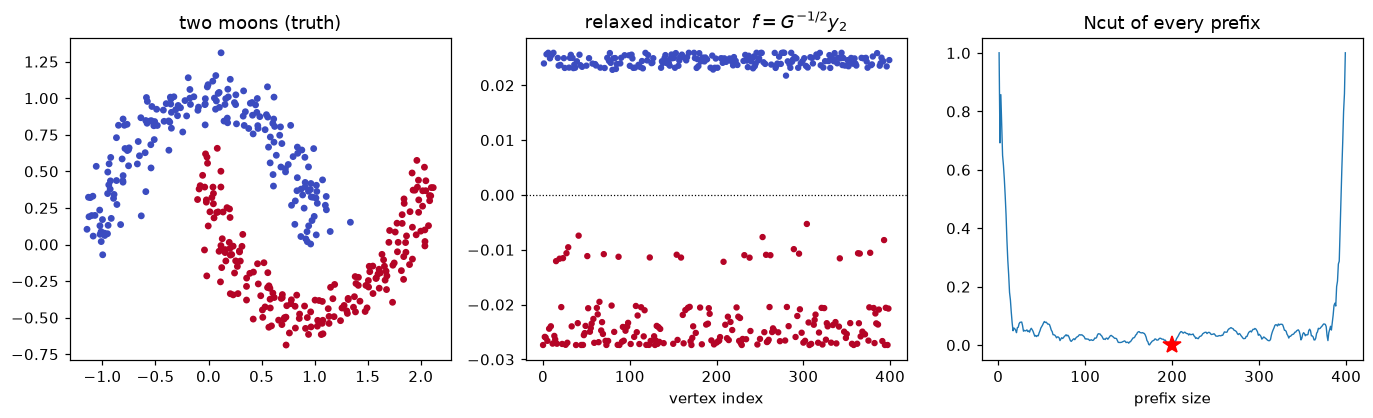

In [5]:
Xm, truth_m = make_moons(n_samples=400, noise=0.10, random_state=1)
cm = np.median(kneighbors_graph(Xm, 10, mode="distance", include_self=False).data ** 2)
Wm = knn_graph(Xm, 10, cm)

vals_m, vecs_m, dm = eigen_embedding(Wm, 2, normalized=True)
f_relaxed = vecs_m[:, 1] / np.sqrt(dm)              # x = G^-1/2 y, the relaxed indicator

# sweep cut: sort by f, evaluate the true Ncut of every prefix
Wmd = Wm.toarray()
dm_sum = Wmd.sum(axis=1)


def ncut_of(mask):
    cut = Wmd[np.ix_(mask, ~mask)].sum()
    return cut / dm_sum[mask].sum() + cut / dm_sum[~mask].sum()


order = np.argsort(f_relaxed)
sweep = np.array([ncut_of(np.isin(np.arange(len(Xm)), order[:t])) for t in range(1, len(Xm))])
t_best = sweep.argmin() + 1
mask_sweep = np.isin(np.arange(len(Xm)), order[:t_best])
mask_sign = f_relaxed > 0

print(f"components = {connected_components(Wm, directed=False)[0]}, lambda_2 = {vals_m[1]:.2e}")
print(f"threshold at 0           : Ncut = {ncut_of(mask_sign):.4f}, ARI = {adjusted_rand_score(truth_m, mask_sign):.3f}")
print(f"sweep cut (best of {len(Xm) - 1}): Ncut = {sweep.min():.4f}, ARI = {adjusted_rand_score(truth_m, mask_sweep):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(12.6, 3.9))
ax[0].scatter(Xm[:, 0], Xm[:, 1], c=truth_m, s=12, cmap="coolwarm")
ax[0].set_title("two moons (truth)")
ax[1].scatter(np.arange(len(Xm)), f_relaxed, c=truth_m, s=10, cmap="coolwarm")
ax[1].axhline(0.0, color="k", lw=0.8, ls=":")
ax[1].set_title("relaxed indicator  $f=G^{-1/2}y_2$")
ax[1].set_xlabel("vertex index")
ax[2].plot(np.arange(1, len(sweep) + 1), sweep, lw=0.9)
ax[2].plot([t_best], [sweep.min()], "r*", ms=12)
ax[2].set_title("Ncut of every prefix")
ax[2].set_xlabel("prefix size")
plt.tight_layout()
plt.show()


The middle panel is the reason the method works, and it is worth looking at it as a picture of the
*data ordering*: sorted by $f$, the two moons come apart, each moon taking one extreme of the
interval. The coordinate is essentially a step function with a single jump, at the boundary between
the two moons - the relaxation has landed almost exactly on the discrete indicator the data would
need.

The right panel shows the rounding. Here the threshold at zero and the best prefix agree: both split
the moons exactly ($\operatorname{Ncut}$ of order $10^{-4}$, ARI $1.00$), because the eigenvector is
already centred. The sweep is nevertheless the rule to use, for two reasons: it evaluates the
objective we actually care about instead of trusting a threshold at $0$, and it needs one sort and a
running update of the cut. On data with unequal cluster sizes the two rules stop agreeing, and the
sweep is what makes the choice explicit instead of implicit in the sign of an eigenvector.

## 6. The algorithm

Three variants appear in the literature, and they differ only in *which* eigenvectors are taken and
*which* normalisation is applied before K-means.

| variant | matrix | coordinates | normalisation of rows |
|---|---|---|---|
| unnormalized | $L=G-W$ | first $m$ eigenvectors of $L$ (after $\mathbf 1$) | none |
| Shi-Malik (Ncut) | $L_{\text{sym}}$ | first $m$ eigenvectors $y$, then $f=G^{-1/2}y$ | none |
| Ng-Jordan-Weiss | $L_{\text{sym}}$ | first $m$ eigenvectors $y$ | each row scaled to unit length |

The book's Section 14.5.3 does not name a variant; it says "use the eigenvectors of the $m$ smallest
eigenvalues of $L$" - the first row of the table. In practice the normalized version is the one that
survives noise and unbalanced cluster sizes, because the degree normalisation removes the effect of
the varying density that the $k$-nearest-neighbour graph introduces. The row normalisation of the
NJW variant has a different role: if the algorithm took the *ideal* eigenvectors (the indicators of
$m$ components), rows of $Z$ would be vectors of length $1$ pointing at the vertices of a simplex,
one vertex per component, and K-means would find them trivially. Normalising the rows reproduces
that geometry when the eigenvectors are only approximately piecewise constant.

**Algorithm (spectral clustering, $N$ vertices, $K$ clusters).**

1. Build the similarity graph and its weighted adjacency $W$; form $G$ and $L$ (or $L_{\text{sym}}$).
2. Compute the $m$ eigenvectors $y_1,\dots,y_m$ of the $m$ smallest eigenvalues ($y_1$ is the
   trivial constant one, drop it).
3. Form the $N\times m$ matrix $Z$ whose rows are $(y_{2,i},\dots,y_{m+1,i})$, normalise the rows.
4. Cluster the rows of $Z$ with K-means into $K$ clusters; assign vertex $i$ to the cluster of row $i$.

$m$ is usually $K$, or slightly larger. Step 4 is K-means again - the same K-means that failed in
Section 1, but applied in a space where the clusters *are* convex.


In [6]:
labels_un, Z_un, _ = spectral(W, 3, normalized=False)
labels_njw, Z_njw, _ = spectral(W, 3, normalized=True, row_normalize=True)

vals_r, vecs_r, dr = eigen_embedding(W, 3, normalized=True)
Z_sm = vecs_r[:, 1:] / np.sqrt(dr)[:, None]         # f = G^-1/2 y
labels_sm = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(Z_sm)

print("the three variants on the rings (k = 10):")
for name, lab in (("unnormalized L               ", labels_un),
                  ("f = G^-1/2 y, not rescaled  ", labels_sm),
                  ("NJW  unit-length rows       ", labels_njw)):
    print(f"  {name}: ARI = {adjusted_rand_score(truth, lab):.3f}")


the three variants on the rings (k = 10):
  unnormalized L               : ARI = 1.000
  f = G^-1/2 y, not rescaled  : ARI = 0.000
  NJW  unit-length rows       : ARI = 1.000


Two of the three lines recover the rings exactly, and the third fails outright - which is the point of
the exercise. The generalized eigenvector $f=G^{-1/2}y$ is the right object for a *threshold* (or for
Shi and Malik's recursive two-way split), not for K-means: its entries are scaled by $1/\sqrt{g_i}$, and
the degrees of this graph range over three orders of magnitude, so the Euclidean distance that K-means
uses is dominated by a handful of high-degree vertices. Normalising each row to unit length removes
that accident of scale and restores the simplex geometry of the ideal case. This is also why the
unnormalized variant is the one that suffers when the clusters have very different sizes: with $L$
instead of $L_{\text{sym}}$, a large sparse cluster contributes many small coordinates and a small dense
one few large coordinates, and the objective favours the wrong one.

## 7. The book's toy example, reproduced

We now have everything the book does with Figure 14.29, so we can reproduce its four panels: the
second and third eigenvectors plotted against the vertex index, the fifteen smallest eigenvalues, and
the two-dimensional embedding that K-means is run on. The parameters of the figure are: $N=450$,
three rings of $150$, radii $1,2.8,5$, noise $0.25$, $k=10$ neighbours and $m=15$ eigenvalues.


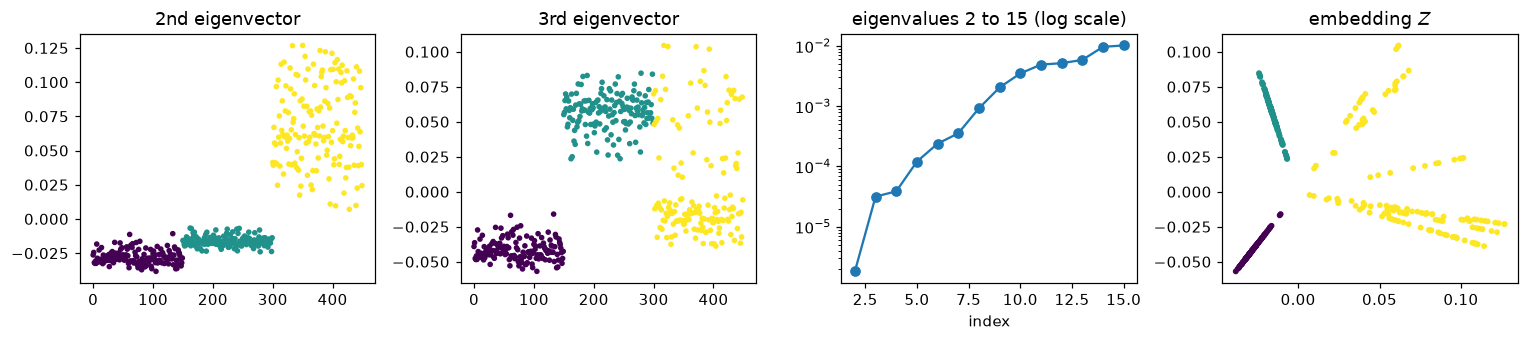

K-means on the embedding, K = 3, m = 2: ARI = 0.780
K-means on the embedding, K = 3, m = 3: ARI = 1.000


In [7]:
vals_fig, vecs_fig, _ = eigen_embedding(W, 15, normalized=True)
Z_fig = vecs_fig[:, 1:3]

fig, ax = plt.subplots(1, 4, figsize=(14.0, 3.2))
ax[0].scatter(np.arange(len(X)), Z_fig[:, 0], c=truth, s=7, cmap="viridis")
ax[0].set_title("2nd eigenvector")
ax[1].scatter(np.arange(len(X)), Z_fig[:, 1], c=truth, s=7, cmap="viridis")
ax[1].set_title("3rd eigenvector")
ax[2].semilogy(np.arange(2, 16), vals_fig[1:15], "o-")
ax[2].set_title("eigenvalues 2 to 15 (log scale)")
ax[2].set_xlabel("index")
ax[3].scatter(Z_fig[:, 0], Z_fig[:, 1], c=truth, s=8, cmap="viridis")
ax[3].set_title("embedding $Z$")
plt.tight_layout()
plt.show()

lab_m2, _, _ = spectral(W, 3, normalized=True, m=2)
lab_m3, _, _ = spectral(W, 3, normalized=True, m=3)
print(f"K-means on the embedding, K = 3, m = 2: ARI = {adjusted_rand_score(truth, lab_m2):.3f}")
print(f"K-means on the embedding, K = 3, m = 3: ARI = {adjusted_rand_score(truth, lab_m3):.3f}")


The two upper panels are the book's Figure 14.29 (bottom left and bottom middle): both eigenvectors
are visibly piecewise constant on the rings, with a different pattern of steps - the second
eigenvector separates the inner ring from the two outer ones, the third splits the outer pair. Each
step is a place where the corresponding coordinate is *the same* for a whole cluster, and that is
what K-means reads.

The third panel is the honest part, and the book says so explicitly about its own figure (p. 547):

> Looking at the top-right panel of Figure 14.29, we see no strong separation between the smallest
> three eigenvalues and the rest. Hence it is not clear how many eigenvectors to select.

There is no gap: the eigenvalues decay gradually, so "how many components are there" cannot be read
off the spectrum here, and $K$ has to come from elsewhere (domain knowledge, a validation criterion,
or the number of eigenvectors that make the embedding stable). The second print line makes the same
point from the other side: with $m=2$ and $K=3$ the three rings have to be carved out of a
*one-dimensional* coordinate and the ARI falls to $0.78$; with $m=3$ it is $1.00$.

A practical recipe that follows from the residual degrees of freedom: choose $m$ slightly larger
than $K$ (the book's own choice, $m=15$ for $K=3$, is generous) and cluster the rows; the extra
coordinates carry the "which side of the ring" information that a single coordinate cannot.


## 8. The graph is the model

Everything up to here treated the graph as given. It is not: it is a modelling decision with two
knobs, the neighbour count $k$ (or the radius $\epsilon$) and the scale $c$ of the kernel. The book
reports what happened when it varied $k$ on this example (p. 547):

> In the toy example of Figure 14.29 we obtained good results for $k\in[5,200]$, the value 200
> corresponding to a fully connected graph. With $k<5$ the results deteriorated.

Both ends of that range are instructive, and they fail for opposite reasons. With too few
neighbours the graph breaks into pieces that are internally connected but mutually isolated; the
eigenvectors then describe the islands, not the rings. With very many neighbours every pair is
connected, and if the weights were all equal the graph would carry no geometry at all - which is why
the kernel weights matter: $w=\exp(-d^2/c)$ lets the far edges be weak, so a nearly complete graph
still encodes distance.

The next cell sweeps $k$ and then $c$, keeping everything else fixed.


   k    ARI  components
   3  0.345          10
   5  0.836           6
   8  1.000           1
  10  1.000           1
  15  0.790           1
  30  0.443           1
  60  0.443           1
 120  0.443           1
 200  0.443           1
 300  0.443           1
 449  0.443           1


 c / c0    ARI
    0.1  0.405
    0.2  0.397
    0.5  1.000
    1.0  1.000
    2.0  1.000
    5.0  1.000
   20.0  1.000


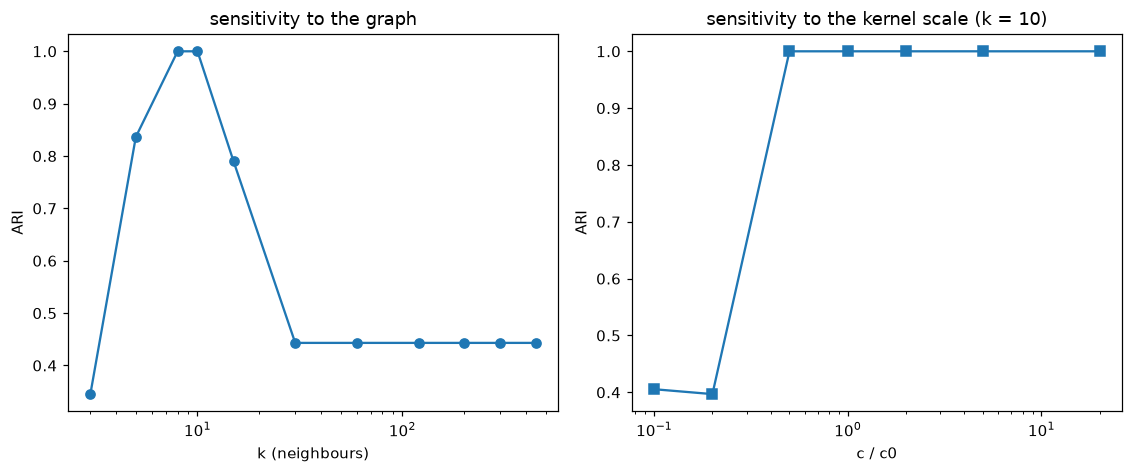

In [8]:
ks = [3, 5, 8, 10, 15, 30, 60, 120, 200, 300, 449]
rows = []
for k in ks:
    Wk = knn_graph(X, k, c0)
    lab_k, _, _ = spectral(Wk, 3, normalized=True)
    nk = connected_components(Wk, directed=False)[0]
    rows.append((k, adjusted_rand_score(truth, lab_k), nk))

print(f"{'k':>4} {'ARI':>6} {'components':>11}")
for k, ari, nk in rows:
    print(f"{k:>4} {ari:>6.3f} {nk:>11}")

fig, ax = plt.subplots(1, 2, figsize=(10.4, 4.4))
ax[0].plot([r[0] for r in rows], [r[1] for r in rows], "o-")
ax[0].set_xscale("log")
ax[0].set_xlabel("k (neighbours)")
ax[0].set_ylabel("ARI")
ax[0].set_title("sensitivity to the graph")

factors = [0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 20.0]
cs = []
for fac in factors:
    Wc = knn_graph(X, 10, fac * c0)
    lab_c, _, _ = spectral(Wc, 3, normalized=True)
    cs.append(adjusted_rand_score(truth, lab_c))
print(f"{'c / c0':>7} {'ARI':>6}")
for fac, ari in zip(factors, cs):
    print(f"{fac:>7.1f} {ari:>6.3f}")
ax[1].semilogx(factors, cs, "s-")
ax[1].set_xlabel("c / c0")
ax[1].set_ylabel("ARI")
ax[1].set_title("sensitivity to the kernel scale (k = 10)")
plt.tight_layout()
plt.show()


The table has the shape the book describes, but its good range is narrower than the book's
$k\in[5,200]$: with the kernel scale pinned at $c_0$ (the median squared distance to the tenth
neighbour), $k=8$ and $k=10$ are perfect, $k=5$ already merges two rings ($0.84$), and every
$k\ge 30$ settles at $0.44$ - the answer you get when the graph is almost complete and the weights
no longer encode locality. The book's wider range comes from its own choice of $c$; the honest
lesson is that $k$ and $c$ are one parameter seen twice, and that quoting a range for one without
the other means little.

The mechanism at the small end is visible in the component column: at $k=3$ the graph falls into ten
pieces, so the smallest eigenvectors describe islands of the rings rather than the rings. At the
large end the graph stays connected but every pair is joined, and the local information that made the
rings separable becomes a small correction on a nearly uniform graph.

The right panel says something more encouraging, and it is worth understanding why. Here the ARI is
insensitive to $c$ over more than an order of magnitude - everything from $0.5c_0$ to $20c_0$ gives
$1.00$ - and it collapses only when $c$ becomes small enough to tear the graph apart ($0.40$ at
$0.1c_0$, and at $0.2c_0$ too). The reason is the $k$-nearest-neighbour construction: it has already
decided which pairs are edges, so the kernel scale only sets the weights of edges that are all short.
On a fully connected graph the same parameter decides which edges matter at all, and then it is much
more delicate. A defensible default, and the one used on this page, is to set $c$ from the data: the
median squared distance to the $k$-th neighbour, so that the typical edge weight is $e^{-1}$.

This is the honest summary of the method: **the algorithm is three lines of linear algebra; the
difficulty is entirely in building the graph.** {cite}`Fayaz2015Spectral` attacks precisely this
difficulty - on MRI images the parameters of the graph are not obvious at all, and the thesis
tunes them with a genetic algorithm, then reuses the tuned values on similar images.


## 9. Application: segmenting a tissue image

The canonical use of spectral clustering outside toy data is image segmentation, and it is the
application of {cite}`Fayaz2015Spectral`: separate the fat tissue in MRI images of athletes' thighs
before and after a training programme. The translation from pixels to a graph is mechanical and
worth seeing once:

* one vertex per pixel (or per downsampled pixel),
* a feature vector per vertex that contains the position $(x,y)$ and the colour or intensity,
* a $k$-nearest-neighbour graph on those features, with RBF weights.

Then a cluster is a set of pixels that are *both* close in the image *and* similar in colour, and
the graph cut is the boundary between two tissues. The relative scaling of position and colour in
the feature vector is one more knob: colour is what distinguishes the tissue classes, position is
what keeps the segments spatially coherent.

The MRI volumes that `scikit-image` downloads were not available when this page was built (they need
network access), so the figure below segments a stained-tissue micrograph instead (immunohistochemistry, shipped with the
library): brown stained epithelium against pale stroma and blue nuclei. It is the same construction
on a different tissue; the thesis builds its $W$ the same way, pixel by pixel.

Note the size: a $1000\times1000$ image has $10^6$ pixels, so $W$ has $10^{12}$ entries. That is the
subject of the next section.


103 x 103 image: 10609 vertices, 198118 edges, 0.18 percent of all pairs


smallest eigenvalues of L_sym: [0.       0.000257 0.000475 0.001538]
exact spectral clustering: 1.97 s, cluster sizes [3817 6288  504]


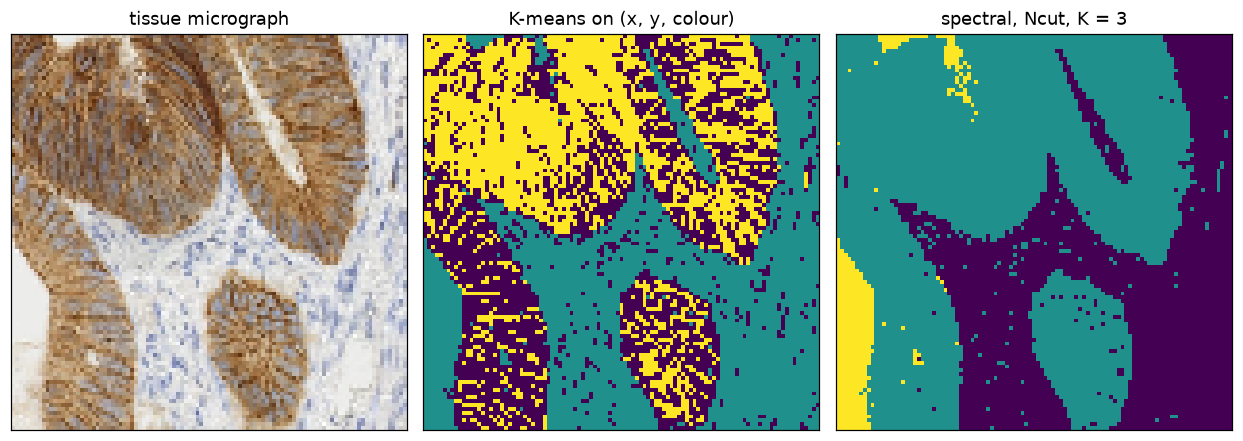

In [9]:
from skimage import data

img = data.immunohistochemistry().astype(float)[::5, ::5]
Hpx, Wpx = img.shape[:2]
yy, xx = np.mgrid[0:Hpx, 0:Wpx]
F = np.column_stack(
    [0.5 * xx.ravel() / Wpx, 0.5 * yy.ravel() / Hpx, 2.0 * img.reshape(-1, 3) / 255.0]
)
ci = np.median(kneighbors_graph(F, 15, mode="distance", include_self=False).data ** 2)
Wi = knn_graph(F, 15, ci)
print(f"{Hpx} x {Wpx} image: {len(F)} vertices, {Wi.nnz} edges, "
      f"{100 * Wi.nnz / len(F) ** 2:.2f} percent of all pairs")

t0 = time.perf_counter()
labels_img, Zi, vals_img = spectral(Wi, 3, normalized=True)
t_full = time.perf_counter() - t0
labels_kmf = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(F)
print(f"smallest eigenvalues of L_sym: {np.round(vals_img[:4], 6)}")
print(f"exact spectral clustering: {t_full:.2f} s, cluster sizes {np.bincount(labels_img)}")

fig, ax = plt.subplots(1, 3, figsize=(11.4, 4.0))
ax[0].imshow(img.astype(int))
ax[0].set_title("tissue micrograph")
ax[1].imshow(labels_kmf.reshape(Hpx, Wpx), cmap="viridis")
ax[1].set_title("K-means on (x, y, colour)")
ax[2].imshow(labels_img.reshape(Hpx, Wpx), cmap="viridis")
ax[2].set_title("spectral, Ncut, K = 3")
for a in ax:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()


The middle panel is the failure mode of a Euclidean metric in a feature space that mixes units: K-means
partitions the *cube* in which the features live into three convex cells, so it scatters the label
over the whole image - patches of the same class appear in unrelated places, and the segments are
not connected sets of pixels. The right panel is a partition of the *graph*: the brown stained tissue
falls in one class, the pale stroma with its nuclei in a second, and the boundaries fall where the
stain jumps, which is where a pathologist would draw them. The third class is the bright strip along
the left edge, an artefact of the section - the price of asking for three segments on an image that
contains two tissues.

Three things are worth noting. First, the spectral algorithm does not know that the vertices are
arranged in a grid; the grid enters only through the position coordinates of the features. Second,
the number of segments is still a choice ($K=3$ here) and the spectrum announces nothing - this
graph's four smallest eigenvalues are all tiny and there is no gap to read a $K$ from. Third,
$N=10\,609$ vertices already needs the sparse path of `eigsh`; the dense matrix would be $900$ MB.
The next section is about what happens when even the sparse route stops fitting.


## 10. When $N$ is too large: the Nystrom approximation

For an image, $N$ is the number of pixels, and the exact route dies quickly. The relevant costs, with
$N$ vertices, a Laplacian with $\mathrm{nnz}$ nonzeros and $m\ll N$ eigenvectors:

| step | dense $L$ | sparse $L$ | Nystrom |
|---|---|---|---|
| memory | $N^2$ | $\mathrm{nnz}$ | $N\ell$ |
| eigenvectors | $O(N^3)$ | $O(\mathrm{nnz}\cdot m)$ per Lanczos step | $O(N\ell+\ell^3)$ |
| $N=10^6$, $\ell=10^3$ | $8$ TB | a few hundred MB | $8$ GB |

At $N=10^6$ the dense matrix alone is $8$ TB, so the sparse route is the only exact one - and
even there the *smallest* eigenvalues are the expensive part: Lanczos converges slowly on them,
and the usual remedy, shift-invert, needs a factorisation of the $10^6\times10^6$ matrix whose
fill-in runs to gigabytes. Nystrom replaces both by an $\ell\times\ell$ dense problem and an
$N\times\ell$ block. The approximation that both
theses use {cite}`Fayaz2015Spectral, Nemati2018Gradient` is Nystrom's method, which is a low-rank
sketch of the affinity. Split the vertices into a sample of size $\ell$ and the rest, and order the
affinity accordingly:

$$W=\begin{bmatrix} A & B\\ B^\top & C\end{bmatrix},\qquad A\in\mathbb{R}^{\ell\times\ell}.$$

If $W$ has rank $r\ll\ell$, the whole matrix is determined by its first $\ell$ rows, because
$C=B^\top A^{-1}B$. So *replace $C$ by that expression* and never compute it:

$$\hat W=\begin{bmatrix}A & B\\ B^\top & B^\top A^{-1}B\end{bmatrix}
=\begin{bmatrix}A\\ B^\top\end{bmatrix}A^{-1}\begin{bmatrix}A & B\end{bmatrix}.$$

The eigenpairs of $\hat W$ come from the small $\ell\times\ell$ problem. With $A=U\Lambda U^\top$, the
raw eigenvector matrix is $\bar U=\begin{bmatrix}U\\ B^\top U\Lambda^{-1}\end{bmatrix}$, whose columns
are not orthonormal. The orthonormal version used in {cite}`Nemati2018Gradient` is

$$V=\begin{bmatrix}A\\ B^\top\end{bmatrix}A^{-1/2}U_Q\Lambda_Q^{-1/2},
\qquad Q=A+A^{-1/2}BB^\top A^{-1/2}=U_Q\Lambda_Q U_Q^\top ,$$

and in a computation one never forms $Q$ that way: since $A^{-1/2}(A^2+BB^\top)A^{-1/2}$ is just the
top-left block of the *squared* affinity, $Q=A^{-1/2}(W^2)_{SS}A^{-1/2}$, which costs an
$N\times\ell$ product. Note the consequences: $V$ has $N$ rows, so the embedding is complete; the
first column of $V$ is the trivial eigenvector (as in the exact problem), so the $m$ coordinates are
columns $2,\dots,m+1$; and the arithmetic never touches an $N\times N$ object.

For spectral clustering the sketch is applied to the *normalized* affinity
$G^{-1/2}WG^{-1/2}$, whose top $m+1$ eigenvectors are the bottom $m+1$ of $L_{\text{sym}}$. The
degree vector can be estimated from the sampled columns ($\hat d$ in the thesis), which is what makes
the method usable at $N=10^6$.

The remaining question is which $\ell$ vertices to sample, and this is the contribution of
{cite}`Nemati2018Gradient`. Uniform sampling is the cheap choice, but it is unstable: a sample that
happens to miss a whole tissue still produces a full-size answer, confidently wrong. The fix is to
sample with probability proportional to the squared norm of the column,

$$P_i=\frac{\|W_{:,i}\|^2}{\|W\|_F^2},$$

the sampling distribution of the randomised low-rank approximation theory (Frieze, Kannan and
Vempala): columns that carry more weight are sampled more often, so the sketch sees them. The thesis
goes further - it samples *incrementally*, adding points in a second pass where the residual is
large, and solves the resulting eigenproblem with conjugate gradients whose step size is tuned by a
genetic algorithm. The next two cells test the part that is cheapest to test: how the sketch's
accuracy depends on $\ell$, and whether the norm-proportional sample beats the uniform one at the
same budget.


In [10]:
def dense_rbf(F, c=None):
    "Affinity exp(-d^2/c) with unit self-similarity on the diagonal, after Fowlkes et al."
    F = np.asarray(F, float)
    D2 = ((F[:, None, :] - F[None, :, :]) ** 2).sum(-1)
    return np.exp(-D2 / (np.median(D2[D2 > 0]) if c is None else c))


def affinity_cols(Ws, idx):
    "The blocks A = Ws[idx][:, idx] and B = Ws[:, idx], as dense arrays."
    if hasattr(Ws, "tocsr"):
        return Ws[idx][:, idx].toarray(), Ws[:, idx].toarray()
    return Ws[np.ix_(idx, idx)], Ws[:, idx]


def nystrom_embedding(Ws, idx, m):
    "The m + 1 largest eigenpairs of the affinity Ws, from an l x l sketch."
    A, B = affinity_cols(Ws, idx)
    ev, evec = np.linalg.eigh(A)
    keep = ev > 1e-8 * ev.max()
    ev, evec = ev[keep], evec[:, keep]
    Ais = (evec / np.sqrt(ev)) @ evec.T                 # A^-1/2
    Q = Ais @ (B.T @ B) @ Ais                           # = A + A^-1/2 B B^T A^-1/2
    qv, qU = np.linalg.eigh(Q)
    order = np.argsort(qv)[::-1][: m + 1]
    qv, qU = qv[order], qU[:, order]
    return (B @ Ais @ qU) / np.sqrt(qv)                 # N x (m + 1), orthonormal columns


d_all = np.asarray(Wi.sum(axis=1)).ravel()
s_all = 1.0 / np.sqrt(d_all)
Ws_all = (diags(s_all) @ Wi @ diags(s_all)).tocsr()

crop = (xx.ravel() < 50) & (yy.ravel() < 50)            # 50 x 50 corner of the same image
Fc = F[crop]
Wc = dense_rbf(Fc)                                      # the theses' W: all pairs, dense
dc = Wc.sum(axis=1)
Wsc = (1.0 / np.sqrt(dc))[:, None] * Wc * (1.0 / np.sqrt(dc))[None, :]

t0 = time.perf_counter()
vals_c, vecs_c = np.linalg.eigh(Wsc)
t_dense = time.perf_counter() - t0
order_c = np.argsort(vals_c)[::-1]
Zc = vecs_c[:, order_c[1:4]]
Zc = Zc / np.linalg.norm(Zc, axis=1, keepdims=True)
labels_exact = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(Zc)

print(f"dense affinity on {len(Fc)} pixels: full eigendecomposition in {t_dense:.2f} s")
print("largest eigenvalues of the normalized affinity")
print("  dense crop (section 10): ", np.round(vals_c[order_c][:6], 4))
print("  kNN graph (section 9):   ", np.round(np.sort(eigsh(Ws_all, k=6, which="LA")[0])[::-1], 4))
print("exact clusters on the crop:", np.bincount(labels_exact))


dense affinity on 2500 pixels: full eigendecomposition in 2.39 s
largest eigenvalues of the normalized affinity
  dense crop (section 10):  [1.     0.7073 0.5613 0.3473 0.2266 0.1418]


  kNN graph (section 9):    [1.     0.9997 0.9995 0.9985 0.9973 0.997 ]
exact clusters on the crop: [940 846 714]


In [11]:
n_c = len(Fc)
p_uni = np.full(n_c, 1.0 / n_c)
p_lev = (Wsc ** 2).sum(axis=0)
p_lev = p_lev / p_lev.sum()

print(f"{'ell':>4} {'percent':>8} {'sampling':>14} {'ARI vs exact':>13} {'sd':>6} {'time':>7}")
for ell in (50, 100, 200, 400):
    for name, p in (("uniform", p_uni), ("norm-weighted", p_lev)):
        out = []
        for seed in range(5):
            idx = np.random.default_rng(seed).choice(n_c, size=ell, replace=False, p=p)
            t0 = time.perf_counter()
            V = nystrom_embedding(Wsc, idx, 3)
            t = time.perf_counter() - t0
            Zv = V[:, 1:] / np.linalg.norm(V[:, 1:], axis=1, keepdims=True)
            lab = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(Zv)
            out.append((adjusted_rand_score(labels_exact, lab), t))
        out = np.array(out)
        print(f"{ell:>4} {100 * ell / n_c:>7.0f}% {name:>14} {out[:, 0].mean():>13.3f} "
              f"{out[:, 0].std():>6.3f} {out[:, 1].mean():>7.3f}")

# the same sketch on the kNN graph of section 9, where the spectrum does not decay
ell = 3000
idx = np.random.default_rng(0).choice(len(F), size=ell, replace=False)
V = nystrom_embedding(Ws_all, idx, 3)
Zv = V[:, 1:]
nrm = np.linalg.norm(Zv, axis=1)
lab = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(
    Zv / np.maximum(nrm[:, None], 1e-12)
)
print(f"kNN graph, ell = {ell} ({100 * ell / len(F):.0f} percent of {len(F)}): "
      f"ARI vs exact = {adjusted_rand_score(labels_img, lab):.3f}, "
      f"empty rows = {np.mean(nrm < 1e-12):.1%}")


 ell  percent       sampling  ARI vs exact     sd    time


  50       2%        uniform         0.663  0.180   0.018


  50       2%  norm-weighted         0.969  0.042   0.006


 100       4%        uniform         0.941  0.076   0.013


 100       4%  norm-weighted         1.000  0.000   0.017


 200       8%        uniform         0.992  0.014   0.024


 200       8%  norm-weighted         1.000  0.000   0.023


 400      16%        uniform         0.999  0.001   0.043


 400      16%  norm-weighted         1.000  0.000   0.112


kNN graph, ell = 3000 (28 percent of 10609): ARI vs exact = 0.041, empty rows = 0.4%


Read the second table in the light of the spectra printed above it. The dense crop's normalized
affinity decays fast ($1, 0.71, 0.56, 0.35, 0.23, \dots$), so a sketch of 100 columns - four percent of
the vertices - already reproduces the exact partition perfectly with norm-proportional sampling, and
almost perfectly with uniform sampling. That is the regime the theses work in, and it is why the
method is worth the effort at $N=10^6$.

The kNN graph of Section 9 is the opposite regime: its normalized affinity has
$1.000, 1.000, 0.999, 0.998, \dots$ - practically no decay, i.e. a large effective rank - and there
the very same sketch, at $\ell=3000$ (28 percent of the vertices), still returns labels uncorrelated
with the exact ones ($\mathrm{ARI}=0.04$). Nothing is wrong with the code: Nystrom's method is a
*rank assumption*, and a graph whose spectrum does not decay violates it. This is the least pleasant fact about the method, and the reason a paper about
speeding up spectral clustering has to say on which graphs it is allowed to help.

Two further remarks on the table. The spread across seeds is what the thesis calls stability: with
uniform sampling the sketch sometimes lands on a sample that misses a stain class, and the error of
that single run is much larger than the average suggests. And the time column is not the point at
this size - at $N=2500$ the full eigendecomposition takes a couple of seconds - but the scaling is: the
sketch's cost is linear in $N$ with a small constant, while the exact cost grows with $N^3$ in the
dense case and with the number of Lanczos steps in the sparse one.


## 11. Where this sits among the other methods on this course

Three connections are worth carrying away.

**It is kernel K-means in disguise.** Cutting the graph with the normalized cut is equivalent to
running K-means in the feature space induced by the kernel $w$, with the cluster centroids weighted
by degree. This is the equivalence {cite}`Fayaz2015Spectral` uses to place spectral clustering next
to the kernel methods of the course, and it explains both the strength (a non-linear metric) and the
weakness ($K$ must be chosen, and the objective is not convex).

**It is the Laplacian version of kernel PCA / MDS.** Section 14.5.4 of {cite}`hastie2009esl` does
kernel PCA; Section 14.9 does manifold maps (Laplacian eigenmaps, local linear embedding,
isomap). Spectral clustering is those embeddings plus the last step of K-means: the eigenvectors of
the graph Laplacian are an embedding that preserves *local* neighbourhoods, and K-means is what
turns the embedding into labels. See [Eigendecomposition](../linear-algebra/Eigendecomposition.ipynb)
for the linear algebra, and [Proximity Matrices and Dissimilarity](Proximity-Matrices-and-Dissimilarity.ipynb)
for the similarity matrix that starts the whole construction.

**It is the third family on the clustering page.** [Three Families of Clustering Algorithms](Three-Families-of-Clustering-Algorithms.ipynb)
separates the methods that optimise a criterion on the data (K-means, K-medoids), the ones that
build a hierarchy ([Hierarchical Clustering](Hierarchical-Clustering.ipynb)), and the ones that
transform the data first. Spectral clustering belongs to the third family, and it is the clearest
example of the principle: when the metric is the problem, change the space, not the optimiser.


## Summary

* K-means fails on non-convex clusters not because of a bad optimum but because its metric is
  Euclidean; spectral clustering replaces the metric with a *graph* built from local neighbourhoods.
* The graph is summarised by $W$, $G$ and $L=G-W$ (14.63). The identity
  $f^\top Lf=\tfrac12\sum_{i,i'}w_{ii'}(f_i-f_{i'})^2$ (14.64) says that the small eigenvectors of
  $L$ are the functions that vary least across edges.
* $L$ has as many zero eigenvalues as there are connected components, and the corresponding
  eigenspace is spanned by the component indicators. This is both the reason the method works and
  the reason the embedding is only defined up to a rotation.
* A cut is the total weight of the edges between two parts. Mincut is degenerate (it isolates single
  vertices); ratio cut and Ncut divide by the sizes or the volumes of the parts, which removes the
  degeneracy.
* Both objectives, relaxed to real-valued indicators, become eigenproblems: ratio cut gives
  $\lambda_2$ of $L$, Ncut gives the second eigenvector of $L_{\text{sym}}$ (equivalently of the
  generalised problem $Lf=\lambda Gf$, with $f=G^{-1/2}y$).
* The algorithm computes $m$ eigenvectors, builds an $N\times m$ matrix of rows, normalises the rows
  and runs K-means on them. The three variants (on $L$, on $L_{\text{sym}}$, and on $L_{\text{sym}}$ with
  rescaled rows) differ only in normalisation - and the rescaling is not cosmetic: without it K-means
  is dominated by the high-degree vertices.
* The parameters of the graph ($k$, $c$, $\epsilon$) and the choice of $m$ and $K$ matter more than
  the choice of variant. Too few neighbours disconnect the graph, too many destroy locality; a
  sensible default is $c$ equal to the median squared distance to the $k$-th neighbour.
* For large $N$, Nystrom sketches the affinity from $\ell$ sampled vertices with cost
  $O(N\ell+\ell^3)$, and sampling proportionally to $\|W_{:,i}\|^2$ is more stable than sampling
  uniformly - the practical contribution of {cite}`Nemati2018Gradient`, applied to tissue
  segmentation in {cite}`Fayaz2015Spectral`.
* The sketch is an assumption, not a free lunch: it works when the spectrum of the affinity decays
  (as it does for a dense kernel) and fails on graphs whose spectrum is flat, where $\ell/N$ has to
  be large before the embedding is faithful.


## Exercises

1. **Counting components.** Show that if $W$ is block diagonal with blocks $W_1,\dots,W_m$, then
   $L$ has $0$ as an eigenvalue with multiplicity at least $m$, and the eigenspace contains the
   indicators of the blocks. What is the multiplicity exactly, and when is it strictly larger?
2. **The constants of the relaxation.** Verify that with
   $f_i=\sqrt{|B|/|A|}$ on $A$ and $f_i=-\sqrt{|A|/|B|}$ on $B$ one gets
   $\|f\|^2=N$ and $f^\top Lf=N\cdot\operatorname{RatioCut}(A,B)$. Then redo the computation with
   the volumes in place of the counts and show that $f^\top Gf=\operatorname{vol}(V)$ and
   $f^\top Lf/f^\top Gf=\operatorname{Ncut}(A,B)$.
3. **Why the second eigenvector.** On the rings graph, compute the relaxed indicator for the ratio
   cut and plot it against the vertex index. Which ring does it isolate, and does the sign of the
   eigenvector ever matter?
4. **Mincut by hand.** On the $10$-vertex graph of Section 4, find a partition whose cut is smaller
   than the Ncut-optimal one but whose Ncut is larger. Compute both objectives for the partition
   "outlier and its nearest blob" versus "outlier alone".
5. **The graph is the model.** Take the two-moons data with noise $0.2$ (instead of $0.10$) and
   sweep $k\in\{3,5,10,20,50\}$. Report the ARI, the number of connected components, and $\lambda_2$.
   Which of the three predicts the quality of the answer best?
6. **Scaling.** Show that $C=B^\top A^{-1}B$ is exact when $\operatorname{rank}(W)=\ell$, and that
   the Nystrom approximation is exact on a graph with $\ell$ connected components made of cliques.
   Then argue why the approximation is poor on a graph whose spectrum decays slowly.


## Sources

* The method, Figure 14.29, equations (14.63)-(14.64) and the remarks on $k$: Section 14.5.3 of
  {cite}`hastie2009esl`, pp. 544-547.
* Normalized cuts, the cut-based derivation and the application to MRI segmentation: the M.Sc.
  thesis of Tayyebe Fayaz {cite}`Fayaz2015Spectral` (Chapters 2 and 4). The image segmented on this
  page is a stained-tissue micrograph bundled with `scikit-image`, not one of the thesis's MRI
  slices.
* The Nystrom approximation of the graph eigenproblem, the orthonormal eigenvector formula, and
  probabilistic incremental sampling: the M.Sc. thesis of Mehdi Nemati {cite}`Nemati2018Gradient`
  (Chapter 2).
* The proofs of the relaxation, the sweep cut and Cheeger's inequality follow the tutorial of
  von Luxburg that the book cites as its source for this section.
